# 01 · Data loading and preprocessing

Phase 1 of the reimplementation of Indian Patent No. 601763, *System and Method for Predicting a State of a Heart Using a Hybrid Fuzzy Membership Model*.

The patent does not name its dataset, but its sample counts (919 rows for the fuzzy model, a 184-row test set for the deep-learning baseline) match the **UCI Heart Disease** dataset: 920 patients from four hospitals (Cleveland, Hungary, Switzerland, VA Long Beach) with a 0–4 target `num`.

This notebook walks through what `scripts/phase1_preprocess.py` does and explains the decisions along the way. All logic lives in `src/hfm/`; the notebook only calls it.

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hfm import config, data, plotting
from hfm.preprocess import fit_transform_split, fitted_numeric_stats, feature_groups

plotting.use_style()
pd.set_option("display.width", 120)

## 1. Raw data

Sixteen columns: an `id`, the source hospital (`dataset`), thirteen clinical attributes, and the target `num`.

In [2]:
raw = data.load_raw()
print(raw.shape)
raw.head()

(920, 16)


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [3]:
raw[config.RAW_TARGET].value_counts().sort_index().rename("patients").to_frame().T

num,0,1,2,3,4
patients,411,265,109,107,28


### Zeros that mean "missing"

A resting blood pressure or a serum cholesterol of 0 is not a measurement. 172 rows carry `chol == 0`, nearly all from Switzerland, and one row has `trestbps == 0`. Left as-is they would drag the imputation mean of cholesterol down from about 244 to about 199, so `clean_raw` converts them to NaN before anything else.

In [4]:
for col in config.ZERO_MEANS_MISSING:
    n = (raw[col] == 0).sum()
    print(f"{col:9s} zero values: {n:4d}   mean with zeros {raw[col].mean():6.1f}   mean without {raw.loc[raw[col] > 0, col].mean():6.1f}")
raw.loc[raw["chol"] == 0, config.SITE_COL].value_counts()

trestbps  zero values:    1   mean with zeros  132.1   mean without  132.3
chol      zero values:  172   mean with zeros  199.1   mean without  246.8


dataset
Switzerland      123
VA Long Beach     49
Name: count, dtype: int64

## 2. From `num` (0–4) to Low / Moderate / High

The patent reports results for three classes but never says how they were derived from the data. `num = 0` means less than 50% diameter narrowing in any major vessel; `num ≥ 1` means angiographically significant disease, and the integer is commonly read as the number of affected vessels.

Two candidate mappings are implemented in `config.RISK_MAPPINGS`:

| name | Low | Moderate | High | class sizes |
|---|---|---|---|---|
| **`default`** (used) | 0 | 1 | 2, 3, 4 | 411 / 265 / 244 |
| `severe_only` | 0 | 1, 2 | 3, 4 | 411 / 374 / 135 |

**Why `default`:** it separates *no significant disease* from *single-vessel* from *multi-vessel* disease, which is a clinically meaningful escalation, and it leaves the High class with enough support (244, of which 49 land in the test split) for stratified cross-validation and data-driven rule generation. `severe_only` leaves only 135 High patients, 28 of them `num = 4`, which is thin for a 3-class model.

Neither mapping reproduces the class supports printed in the patent (High 450, Moderate 355, Low 114 of 919). Those cannot come from any monotone grouping of `num`, so the patent's labels were probably derived another way. This is documented rather than reverse-engineered.

In [5]:
df = data.load_dataset()  # clean_raw + risk label
pd.crosstab(df[config.RAW_TARGET], df[config.TARGET], margins=True)

risk,Low,Moderate,High,All
num,,,,
0,411,0,0,411
1,0,265,0,265
2,0,0,109,109
3,0,0,107,107
4,0,0,28,28
All,411,265,244,920


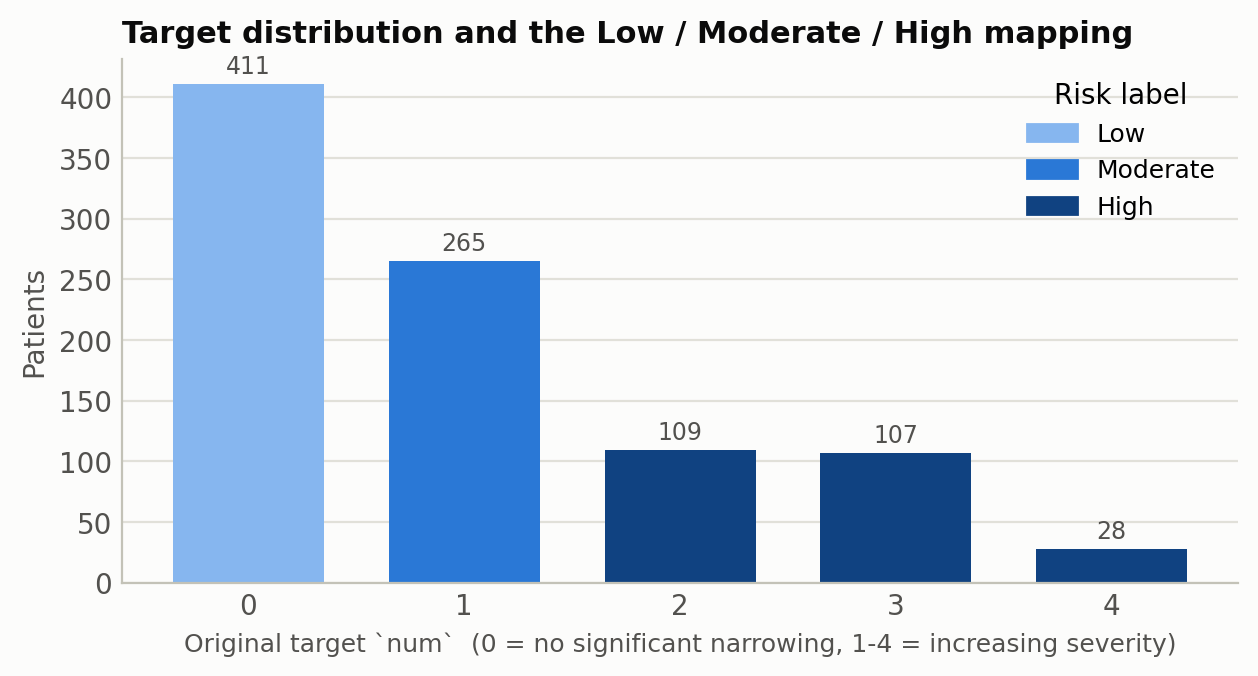

In [6]:
from IPython.display import Image
Image("../figures/01_target_distribution.png", width=640)

## 3. Missingness is not random

Each hospital recorded a different subset of attributes. Switzerland has no cholesterol, Hungary and VA mostly skipped the fluoroscopy (`ca`) and thalassemia (`thal`) tests. Mean / mode imputation (as the patent describes) fills these in, but it is worth remembering that for `ca`, `thal` and `slope` the imputed value is the *majority* of the column.

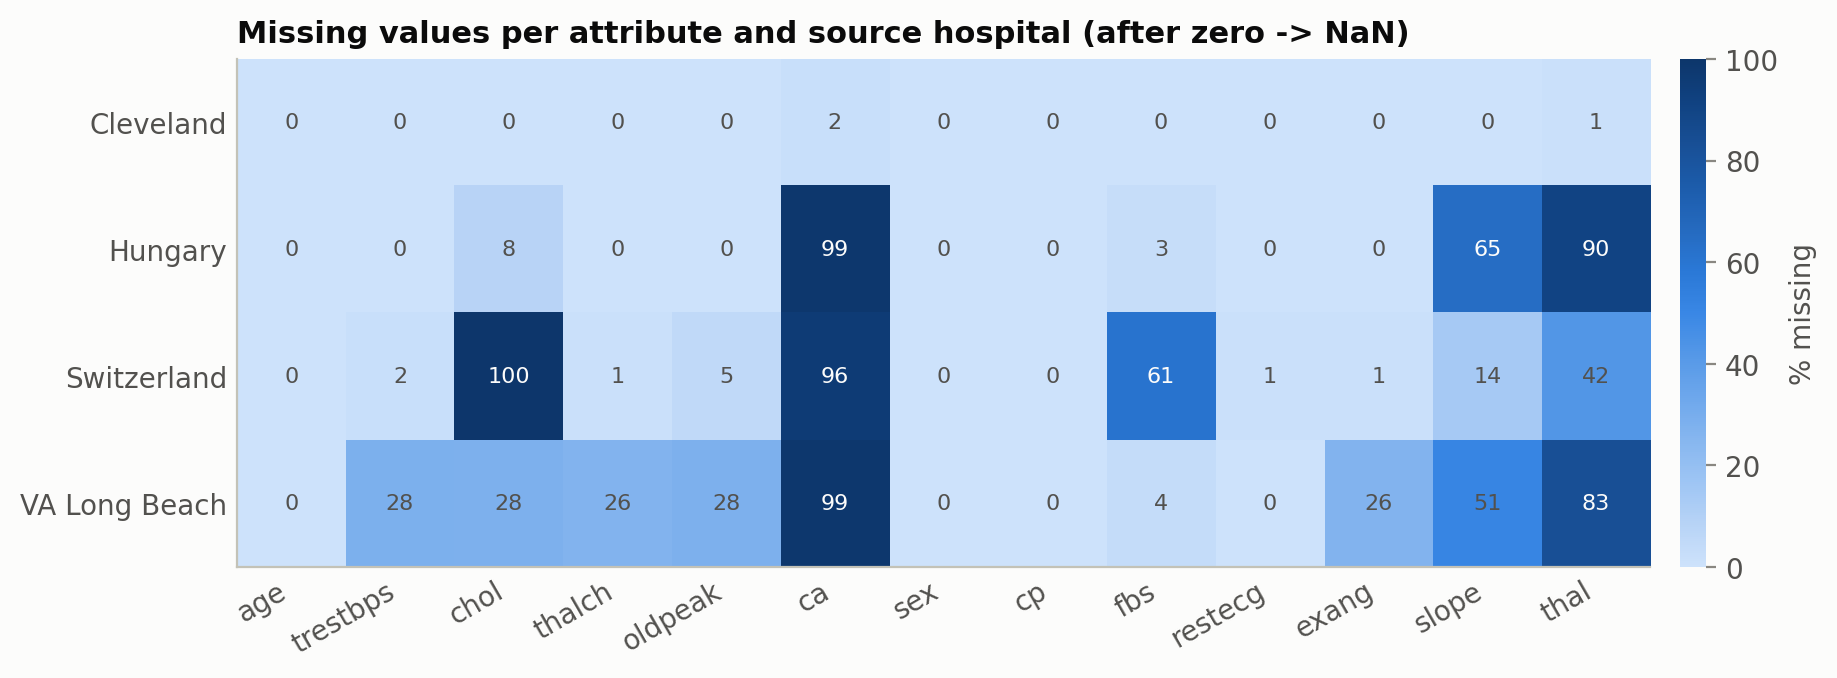

In [7]:
Image("../figures/01_missingness_by_site.png", width=820)

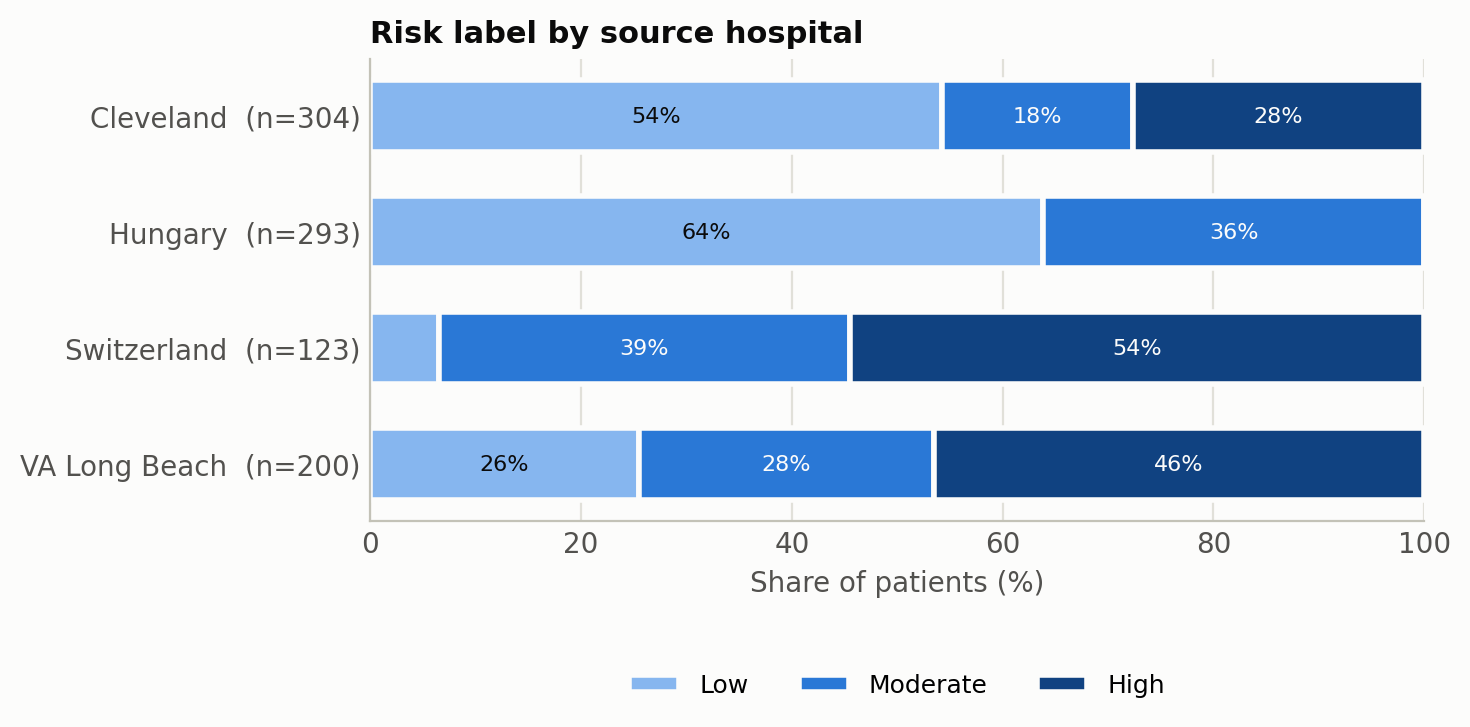

In [8]:
Image("../figures/01_risk_by_site.png", width=680)

Hungary has no patient above `num = 1`, so no High-risk patients at all. The source hospital is therefore a strong proxy for the label. It is **excluded from the feature set** on purpose: a model that predicts risk from the name of the hospital is not a cardiac prediction model.

## 4. Stratified split, then fit on train only

The split is drawn *before* any statistic is computed. The split is stratified on the risk label and seeded, giving 736 training and 184 test rows (the same test size the patent's deep-learning baseline used).

In [9]:
train, test = data.make_split(df)
X_train, y_train = data.split_xy(train)
X_test, y_test = data.split_xy(test)
pd.concat([y_train.value_counts(), y_test.value_counts()], axis=1, keys=["train", "test"])

,train,test
risk,,
Low,329,82
Moderate,212,53
High,195,49


### The preprocessing transformer

`build_preprocessor` is a scikit-learn `ColumnTransformer` with three branches:

| branch | columns | steps |
|---|---|---|
| continuous | age, trestbps, chol, thalch, oldpeak | IQR clip → mean impute → scale |
| discrete | ca | mean impute → scale |
| categorical | sex, cp, fbs, restecg, exang, slope, thal | mode impute → one-hot |

Three deviations from the patent text, each for a reason:

1. **Outliers are clipped, not removed.** Dropping rows from a held-out set changes what is being evaluated. Winsorising to Tukey fences (Q1 − 1.5·IQR, Q3 + 1.5·IQR) keeps every patient.
2. **Clipping happens before imputation, on observed values only.** Doing it afterwards on a 66%-missing column like `ca` makes Q1 = Q3 = the mean and clips every real value away. The discrete vessel count is never clipped at all.
3. **Categoricals use the mode.** A category has no mean.

Only one scaler is applied at a time: `standard` (default for the baselines), `minmax`, or `none` (what the fuzzy phases will use so that membership functions stay in clinical units).

In [10]:
Xtr, Xte, pre = fit_transform_split(X_train, X_test, scaler="standard")
fitted_numeric_stats(pre).round(2)

,mean,clip_lower,clip_upper
age,53.39,27.50,79.50
trestbps,131.35,90.00,170.00
chol,243.97,106.38,377.38
thalch,137.61,66.00,210.00
oldpeak,0.85,-2.25,3.75
ca,0.67,NaN,NaN


Note the cholesterol mean of about 244 mg/dl: that is the mean of real measurements, not of the zero-padded column.

In [11]:
print(Xtr.shape, Xte.shape)
Xtr.head()

(736, 22) (184, 22)


,age,trestbps,chol,thalch,oldpeak,ca,sex_Male,cp_asymptomatic,cp_atypical angina,cp_non-anginal,...,restecg_lv hypertrophy,restecg_normal,restecg_st-t abnormality,exang_True,slope_downsloping,slope_flat,slope_upsloping,thal_fixed defect,thal_normal,thal_reversable defect
0,-1.843737,-0.081581,-7.585404e-01,1.618987,-0.827584,2.069743e-16,1.0,0.0,0.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.594986,0.160631,-8.669944e-01,0.977677,-0.052955,2.475491e+00,1.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.677391,-1.292641,6.730525e-01,-0.785926,0.140702,6.112324e-01,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3,0.382923,1.492797,-1.539409e+00,-0.745844,2.077273,2.069743e-16,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
4,0.170860,-0.687111,6.164897e-16,-1.828055,-0.537098,2.069743e-16,1.0,1.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [12]:
# Proof of no leakage: training columns are centred, test columns are merely transformed.
pd.DataFrame({"train mean": Xtr[config.NUMERIC_COLS].mean(), "test mean": Xte[config.NUMERIC_COLS].mean()}).round(3)

,train mean,test mean
age,-0.0,0.065
trestbps,0.0,0.154
chol,0.0,0.090
thalch,-0.0,-0.010
oldpeak,0.0,0.062
ca,0.0,0.013


### Attribute → encoded columns

Later phases (BBSO feature selection, fuzzy rules) reason about the thirteen *clinical attributes*, not the 22 encoded columns. `feature_groups` provides the lookup.

In [13]:
for attr, cols in feature_groups(pre).items():
    print(f"{attr:9s} -> {cols}")

age       -> ['age']
trestbps  -> ['trestbps']
chol      -> ['chol']
thalch    -> ['thalch']
oldpeak   -> ['oldpeak']
ca        -> ['ca']
sex       -> ['sex_Male']
cp        -> ['cp_asymptomatic', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina']
fbs       -> ['fbs_True']
restecg   -> ['restecg_lv hypertrophy', 'restecg_normal', 'restecg_st-t abnormality']
exang     -> ['exang_True']
slope     -> ['slope_downsloping', 'slope_flat', 'slope_upsloping']
thal      -> ['thal_fixed defect', 'thal_normal', 'thal_reversable defect']


## Outputs

`scripts/phase1_preprocess.py` writes the splits to `data/processed/` (git-ignored, regenerable) and the three figures above to `figures/`.

**Next phase:** baselines (logistic regression, random forest, a small Keras MLP) on `train_processed` / `test_processed`.